# DBSCAN Clustering on Uber Pickup Locations

This Pattern Recognition project implements **DBSCAN (Density-Based Spatial Clustering of Applications with Noise) from scratch** using Uber pickup coordinates.

The notebook explores how `eps` and `min_samples` affect cluster formation and identifies:
- **Core points:** points with at least `min_samples` neighbors in their epsilon-neighborhood (including themselves).
- **Border points:** non-core points that belong to a cluster.
- **Noise points:** points that do not belong to any cluster.

The implementation uses NumPy for distance calculations and neighborhood queries. Scikit-learn's DBSCAN is not used for the clustering algorithm.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_FILE = Path("uber-raw-data-apr14.csv")
MAX_SAMPLES = 5000  # Set to None to use all valid rows (may take longer).
EPS_VALUES = [0.1, 0.3, 0.5, 0.7, 1.0]
MIN_SAMPLES_VALUES = [5, 10]

## 2. Load and inspect the dataset

Place `uber-raw-data-apr14.csv` in the same directory as this notebook. The dataset is not bundled with this repository; see the README for dataset instructions.

In [3]:
from pathlib import Path
import pandas as pd

matches = list(Path("/kaggle/input").rglob("uber-raw-data-apr14.csv"))

if not matches:
    raise FileNotFoundError(
        "Dataset not found. Please check that the Uber dataset is attached."
    )

DATA_FILE = matches[0]
print("Dataset found at:", DATA_FILE)

df = pd.read_csv(DATA_FILE)

required_columns = {"Lat", "Lon"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

coordinates_df = df[["Lat", "Lon"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

coordinates_df = coordinates_df[
    coordinates_df["Lat"].between(-90, 90) &
    coordinates_df["Lon"].between(-180, 180)
]

if MAX_SAMPLES is not None:
    coordinates_df = coordinates_df.head(MAX_SAMPLES)

coordinates = coordinates_df.to_numpy(dtype="float64")

print("Original rows:", len(df))
print("Valid samples:", len(coordinates))
print(coordinates_df.head())

Dataset found at: /kaggle/input/datasets/fivethirtyeight/uber-pickups-in-new-york-city/uber-raw-data-apr14.csv
Original rows: 564516
Valid samples: 5000
       Lat      Lon
0  40.7690 -73.9549
1  40.7267 -74.0345
2  40.7316 -73.9873
3  40.7588 -73.9776
4  40.7594 -73.9722


## 3. Standardize the coordinates

As in the original assignment, latitude and longitude are standardized before applying Euclidean distance. This makes the two coordinate dimensions comparable for the algorithm, but the resulting `eps` values are in standardized feature space—not kilometers or meters.

In [4]:
feature_mean = coordinates.mean(axis=0)
feature_std = coordinates.std(axis=0)
feature_std[feature_std == 0] = 1.0

data_norm = (coordinates - feature_mean) / feature_std

print("Normalized data shape:", data_norm.shape)
print("Feature means after scaling:", data_norm.mean(axis=0))
print("Feature standard deviations after scaling:", data_norm.std(axis=0))

Normalized data shape: (5000, 2)
Feature means after scaling: [-1.07155529e-13 -1.11697318e-14]
Feature standard deviations after scaling: [1. 1.]


## 4. Euclidean distance and region query

In [5]:
def euclidean(point_a, point_b):
    """Calculate Euclidean distance between two coordinate vectors."""
    point_a = np.asarray(point_a, dtype=np.float64)
    point_b = np.asarray(point_b, dtype=np.float64)
    return float(np.sqrt(np.sum((point_a - point_b) ** 2)))


def region_query(data, point_idx, eps):
    """Return indices of all points within eps of data[point_idx].

    The point itself is included in its neighborhood, as required by DBSCAN.
    Vectorized NumPy operations avoid a Python-level loop over every point.
    """
    distances = np.linalg.norm(data - data[point_idx], axis=1)
    return np.flatnonzero(distances <= eps).tolist()

print("Example distance:", euclidean(data_norm[0], data_norm[1]))
print("Example neighborhood size:", len(region_query(data_norm, 0, EPS_VALUES[0])))

Example distance: 2.0940766776394035
Example neighborhood size: 33


## 5. DBSCAN implementation from scratch

Labels use:
- `-2`: unvisited
- `-1`: noise
- `0, 1, 2, ...`: cluster IDs

Neighborhoods are cached so each point's region query is calculated at most once during a run.

In [6]:
def dbscan(data, eps, min_samples):
    """Run DBSCAN and return labels plus core, border, and noise index sets."""
    data = np.asarray(data, dtype=np.float64)

    if data.ndim != 2:
        raise ValueError("data must be a 2D array.")
    if eps <= 0:
        raise ValueError("eps must be positive.")
    if min_samples < 1:
        raise ValueError("min_samples must be at least 1.")

    UNVISITED = -2
    NOISE = -1

    n_samples = len(data)
    labels = np.full(n_samples, UNVISITED, dtype=int)
    neighborhood_cache = {}

    def get_neighbors(index):
        if index not in neighborhood_cache:
            neighborhood_cache[index] = region_query(data, index, eps)
        return neighborhood_cache[index]

    cluster_id = 0
    core_points = set()

    for point_idx in range(n_samples):
        if labels[point_idx] != UNVISITED:
            continue

        neighbors = get_neighbors(point_idx)

        if len(neighbors) < min_samples:
            labels[point_idx] = NOISE
            continue

        cluster_id += 1
        labels[point_idx] = cluster_id
        core_points.add(point_idx)

        # Queue-based expansion; a set prevents repeatedly adding the same point.
        seeds = list(neighbors)
        queued = set(seeds)
        cursor = 0

        while cursor < len(seeds):
            neighbor_idx = seeds[cursor]
            cursor += 1

            if labels[neighbor_idx] == NOISE:
                # Previously considered noise; it is now a border point.
                labels[neighbor_idx] = cluster_id
                continue

            if labels[neighbor_idx] != UNVISITED:
                continue

            labels[neighbor_idx] = cluster_id
            neighbor_neighbors = get_neighbors(neighbor_idx)

            if len(neighbor_neighbors) >= min_samples:
                core_points.add(neighbor_idx)
                for candidate in neighbor_neighbors:
                    if candidate not in queued:
                        seeds.append(candidate)
                        queued.add(candidate)

    noise_points = set(np.flatnonzero(labels == NOISE).tolist())
    clustered_points = set(np.flatnonzero(labels >= 0).tolist())
    border_points = clustered_points - core_points

    return labels, core_points, border_points, noise_points


print("DBSCAN function is ready.")

DBSCAN function is ready.


## 6. Run one configuration

In [7]:
example_eps = 0.3
example_min_samples = 5

start_time = time.time()
labels, core_points, border_points, noise_points = dbscan(
    data_norm, eps=example_eps, min_samples=example_min_samples
)
elapsed = time.time() - start_time

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

print(f"eps={example_eps}, min_samples={example_min_samples}")
print("Number of clusters:", n_clusters)
print("Core points:", len(core_points))
print("Border points:", len(border_points))
print("Noise points:", len(noise_points))
print(f"Runtime: {elapsed:.2f} seconds")

eps=0.3, min_samples=5
Number of clusters: 9
Core points: 4854
Border points: 15
Noise points: 131
Runtime: 0.64 seconds


## 7. Visualize core, border, and noise points

The clustering is performed in standardized feature space, but the chart uses the original longitude and latitude values for geographic interpretability.

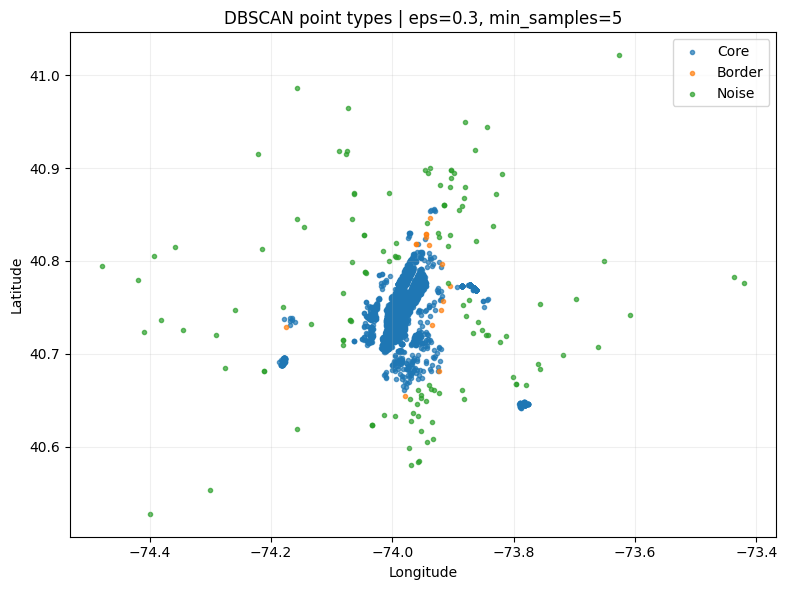

In [8]:
def plot_point_types(coordinates, core_points, border_points, noise_points, title):
    plt.figure(figsize=(8, 6))

    if core_points:
        idx = np.array(sorted(core_points), dtype=int)
        plt.scatter(coordinates[idx, 1], coordinates[idx, 0],
                    s=9, label="Core", alpha=0.7)

    if border_points:
        idx = np.array(sorted(border_points), dtype=int)
        plt.scatter(coordinates[idx, 1], coordinates[idx, 0],
                    s=9, label="Border", alpha=0.7)

    if noise_points:
        idx = np.array(sorted(noise_points), dtype=int)
        plt.scatter(coordinates[idx, 1], coordinates[idx, 0],
                    s=9, label="Noise", alpha=0.7)

    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


plot_point_types(
    coordinates, core_points, border_points, noise_points,
    f"DBSCAN point types | eps={example_eps}, min_samples={example_min_samples}"
)

## 8. Compare different eps and min_samples values

In [9]:
experiment_results = []

for eps in EPS_VALUES:
    for min_samples in MIN_SAMPLES_VALUES:
        start_time = time.time()
        run_labels, run_core, run_border, run_noise = dbscan(
            data_norm, eps=eps, min_samples=min_samples
        )
        runtime = time.time() - start_time
        cluster_count = len(set(run_labels)) - (1 if -1 in run_labels else 0)

        experiment_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": cluster_count,
            "core_points": len(run_core),
            "border_points": len(run_border),
            "noise_points": len(run_noise),
            "noise_percentage": 100 * len(run_noise) / len(run_labels),
            "runtime_seconds": runtime
        })

results_df = pd.DataFrame(experiment_results)
display(results_df)

,eps,min_samples,clusters,core_points,border_points,noise_points,noise_percentage,runtime_seconds
0,0.1,5,23,4659,36,305,6.10,0.307201
1,0.1,10,17,4494,113,393,7.86,0.304885
2,0.3,5,9,4854,15,131,2.62,0.552081
3,0.3,10,6,4763,56,181,3.62,0.547158
4,0.5,5,7,4905,20,75,1.50,0.918424
5,0.5,10,4,4856,37,107,2.14,0.847225
6,0.7,5,5,4935,16,49,0.98,1.216357
7,0.7,10,4,4902,30,68,1.36,1.182303
8,1.0,5,5,4955,8,37,0.74,1.641332
9,1.0,10,4,4931,28,41,0.82,1.660624


## 9. Visualize cluster assignments for selected configurations

/tmp/ipykernel_50/322726889.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", max(len(unique_labels), 1))


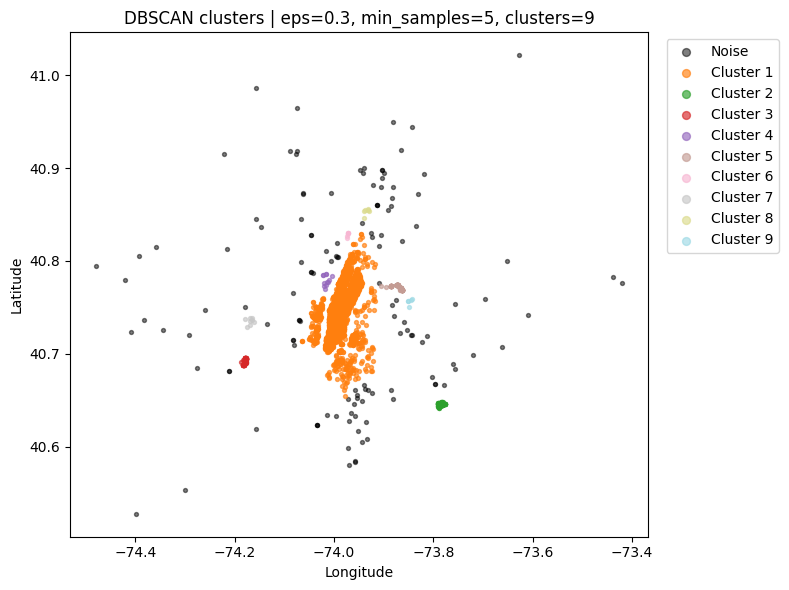

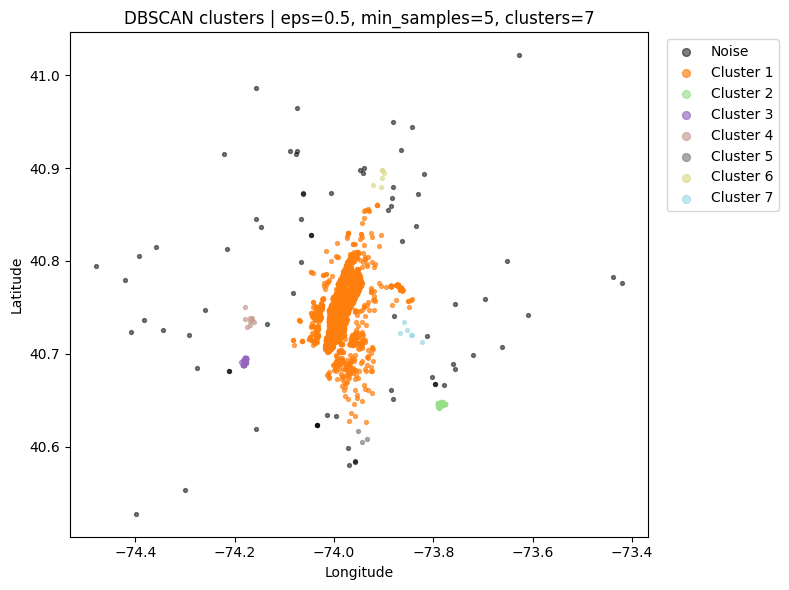

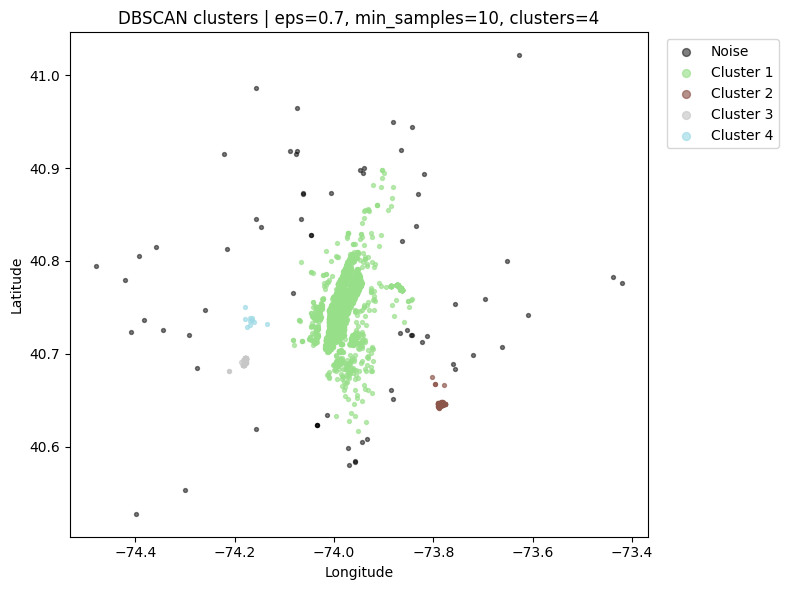

In [10]:
def plot_clusters(coordinates, labels, title):
    plt.figure(figsize=(8, 6))
    unique_labels = sorted(set(labels))
    cmap = plt.cm.get_cmap("tab20", max(len(unique_labels), 1))

    for color_index, label in enumerate(unique_labels):
        mask = labels == label
        if label == -1:
            plt.scatter(
                coordinates[mask, 1], coordinates[mask, 0],
                c="black", s=8, label="Noise", alpha=0.5
            )
        else:
            plt.scatter(
                coordinates[mask, 1], coordinates[mask, 0],
                color=cmap(color_index), s=8, label=f"Cluster {label}", alpha=0.65
            )

    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(title)
    plt.legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


for eps, min_samples in [(0.3, 5), (0.5, 5), (0.7, 10)]:
    run_labels, _, _, _ = dbscan(data_norm, eps=eps, min_samples=min_samples)
    cluster_count = len(set(run_labels)) - (1 if -1 in run_labels else 0)
    plot_clusters(
        coordinates, run_labels,
        f"DBSCAN clusters | eps={eps}, min_samples={min_samples}, clusters={cluster_count}"
    )

## 10. Interpretation and limitations

- Increasing `eps` generally makes neighborhoods larger and can merge nearby clusters.
- Increasing `min_samples` makes the core-point density requirement stricter.
- Noise points are observations that were not assigned to any cluster.
- The current implementation uses Euclidean distance after standardizing latitude and longitude, matching the assignment's approach. This is useful for demonstrating DBSCAN, but it is not a true geographic distance in kilometers.
- The notebook uses up to 5,000 rows by default to keep the from-scratch implementation practical. Set `MAX_SAMPLES = None` to use all valid records, understanding that runtime will increase.
- DBSCAN is sensitive to the choice of `eps` and `min_samples`; interpret the parameter comparison rather than assuming one setting is universally best.